# 25 — Revisión de predicciones

## Pregunta y alcance

El cuaderno 24 mostró que el modelo, entrenado solo hasta el 31 de diciembre de 2025, predijo septiembre de 2026 con
un error del 6 %. Septiembre resultó ser el mes más tranquilo del año, de modo que ese resultado no basta para
juzgar el modelo. Este cuaderno lo enfrenta a los meses más difíciles de 2026 y a un mes que todavía no ha ocurrido:

- **marzo, julio y agosto de 2026**, predichos desde el 31 de diciembre de 2025, sin reentrenar;
- **octubre de 2026**, predicho desde el 20 de septiembre, el último día con datos. Es una predicción prospectiva: se
  guardó con fecha antes de que existiera el dato y se verifica a medida que el mes transcurre.

Para cada día se compara el valor anunciado con el real y se juzga si el modelo acertó que el día subiría, bajaría o
quedaría en lo normal.

## Contenido

1. Por qué estos meses.
2. El diseño de la revisión.
3. Marzo de 2026.
4. Julio de 2026.
5. Agosto de 2026.
6. Los meses juntos, con septiembre.
7. Octubre de 2026: la predicción guardada.
8. Límites del análisis.

In [1]:
import sys, json, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path[:0] = [str(RAIZ), str(RAIZ / "notebooks")]; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from IPython.display import Markdown, display
import statsmodels.api   # se importa antes: al importarse reinstala su filtro de avisos
from scipy.stats import norm
import pronostico as pr, semana as sm, mes_a_ciegas as mac

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
DC = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
MESES = ["", "enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
         "noviembre", "diciembre"]
num = lambda x, d=1: f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")
fecha_larga = lambda t: f"{DIAS[t.dayofweek]} {t.day}"

serie = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
serie = serie.set_index("dia").triages.astype(float).loc[:mac.ULTIMO_DATO]
serie["2024-03-19":"2024-03-21"] = np.nan
REP = mac.reportado()                                     # conteos de fuente externa, escritos a mano
REAL = serie.combine_first(REP)
print(f"Triage en salidas/ hasta el {mac.ULTIMO_DATO}; conteos reportados a mano: {len(REP)} días"
      + (f" ({REP.index.min().date()} a {REP.index.max().date()})." if len(REP) else "."))

Triage en salidas/ hasta el 2026-09-20; conteos reportados a mano: 7 días (2026-09-21 a 2026-09-27).


---
# 1. Por qué estos meses

Se midió, para cada mes de 2026, cuánto cambió el nivel frente al mes anterior, qué tan errático fue cada día frente
al mismo día de la semana en las ocho semanas previas, cuántos días se salieron más de un 15 % de ese valor y cuánto
se equivocó un modelo a ciegas ya existente (el SARIMAX sin contexto entrenado hasta el 31 de diciembre de 2025). Los
meses se eligieron con esta tabla, antes de predecirlos.

In [2]:
ly = np.log(serie)
ref8 = pd.concat([ly.shift(7 * k) for k in range(1, 9)], axis=1).mean(axis=1)
dev = (ly - ref8)["2026"]
m = serie.resample("MS").mean()
a = pd.read_parquet(RAIZ / "salidas/pronostico/e1/anio/sarimax.parquet").dropna(subset=["real"])
a = a[a.fecha <= mac.ULTIMO_DATO]
err = (100 * abs(a.q50 - a.real) / a.real).groupby(a.fecha.dt.to_period("M")).mean()
DIF = pd.DataFrame({"media por día": m["2026"].values,
                    "cambio frente al mes anterior %": (100 * (m / m.shift(1) - 1))["2026"].values,
                    "variabilidad diaria %": (100 * dev.resample("MS").std()).values,
                    "días a más de 15 % de lo normal": (dev.abs() > np.log(1.15)).resample("MS").sum().values,
                    "error de un modelo a ciegas %": err.values},
                   index=[MESES[t.month] for t in m["2026"].index])
display(DIF.style.format(precision=1).format("{:.0f}", subset=["días a más de 15 % de lo normal"]))

,media por día,cambio frente al mes anterior %,variabilidad diaria %,días a más de 15 % de lo normal,error de un modelo a ciegas %
enero,151.8,2.7,14.5,12,12.4
febrero,148.8,-2.0,12.3,7,12.0
marzo,191.4,28.7,11.3,27,16.6
abril,183.7,-4.0,11.8,7,14.1
mayo,190.5,3.7,10.1,6,12.5
junio,197.7,3.8,13.9,10,10.5
julio,163.7,-17.2,10.8,16,9.1
agosto,148.8,-9.1,20.5,18,18.5
septiembre,178.4,19.9,8.2,9,4.5


A partir de la tabla anterior se eligieron tres meses, cada uno difícil por una razón distinta:

- **Marzo: un salto de nivel.** Los afiliados de Nueva EPS volvieron (de 53 a 89 triages por día) y el volumen subió
  un 28,7 % en un mes; 27 días quedaron a más de un 15 % de lo que venía siendo normal.
- **Julio: un desplome.** Nueva EPS volvió a caer (de 95 a 52 por día) y el volumen bajó un 17,2 %.
- **Agosto: un golpe y el desorden.** El terremoto del lunes 10 llevó ese día a 108 triages, cuando un lunes normal
  ronda los 200; es el mes más errático del año (variabilidad del 20,5 %) y el de mayor error para el modelo a ciegas
  existente. Tuvo además dos festivos, el 7 y el 17.

Septiembre, en cambio, es el mes más tranquilo: la menor variabilidad (8,2 %) y el menor error (4,5 %).

---
# 2. El diseño de la revisión

**El modelo** es el del cuaderno 24, sin cambios: M3s (SARIMAX y LightGBM con los mecanismos externos medidos, sin
la fase fuerte de la COVID y sin el terremoto), con tres referencias: C0r (la misma combinación sin contexto
externo), lo normal del calendario (regresión de calendario y estación con el nivel del origen) y el mismo día de
hace 52 semanas. No se reentrenó nada para elegir o ajustar.

| Mes | Datos hasta | Adelanto | Tipo |
|---|---|---|---|
| Marzo de 2026 | 31 de diciembre de 2025 | 59 a 89 días | verificable |
| Julio de 2026 | 31 de diciembre de 2025 | 181 a 211 días | verificable |
| Agosto de 2026 | 31 de diciembre de 2025 | 212 a 242 días | verificable |
| Octubre de 2026 | 20 de septiembre de 2026 | 11 a 41 días | prospectiva |

**Sube, normal o baja.** Lo normal de cada día es la media del mismo día de la semana en las ocho semanas anteriores
al mes (para octubre, las ocho semanas que terminan el 20 de septiembre, lo último conocido). Un día **sube** si
queda más de un 5 % por encima de ese valor, **baja** si queda más de un 5 % por debajo, y es **normal** en medio. La
banda del 5 % reparte los días en tres grupos de tamaño parecido, dado que el ruido diario del hospital es del
12,6 %. La categoría que anuncia el modelo es la de su valor esperado; las tres probabilidades salen de sus cuantiles.

**La tasa base.** Si en un mes casi todos los días suben, decir siempre «sube» acierta mucho sin saber nada. Por eso
cada mes reporta, junto al acierto del modelo, el acierto de decir siempre la categoría más frecuente de ese mes.

In [3]:
filas = []
for o in sorted(set(mac.MESES_REVISION.values())):
    y, _ = mac.datos("m3s_ciego", pd.Timestamp(o) + pd.Timedelta(days=1))
    e = y.loc[:o]
    filas.append({"datos hasta": o, "primer día": str(e.index.min().date()), "días usados": int(e.notna().sum()),
                  "fuera (COVID fuerte y caída de registro)": int(e.isna().sum()), "registros usados": int(e.sum()),
                  "media por día": e.mean(), "días de 2026": int(e[e.index.year == 2026].notna().sum())})
display(pd.DataFrame(filas).set_index("datos hasta").style.format(precision=1, thousands=".", decimal=",")
        .set_caption("Registros con que se entrenó cada predicción"))
pr.FIN = mac.ULTIMO_DATO

,primer día,días usados,fuera (COVID fuerte y caída de registro),registros usados,media por día,días de 2026
datos hasta,,,,,,
2025-12-31,2020-01-01,2.019,173,374.388,"185,4",0
2026-09-20,2020-01-01,2.282,173,419.794,"184,0",263


In [4]:
VAL = mac.leer(); VAL = VAL[(VAL.modelo == "M3s") & (VAL.anio < 2026)].dropna(subset=["real"])
rho_l = []
for _, g in VAL.groupby("anio"):
    z = norm.ppf(sm.pit(g[pr.QCOL].values, g.real.values)); rho_l.append(np.corrcoef(z[:-1], z[1:])[0, 1])
_, rhos_sem = sm.resumen_validacion(pd.read_parquet(sm.CARPETA / "validacion_semanal.parquet"), sm.datos()[0])
RHO = {"2025-12-31": float(np.mean(rho_l)), mac.ULTIMO_DATO: rhos_sem[("M3s", 15)]}
cat = lambda v, r: np.where(v > r * (1 + mac.BANDA), "sube", np.where(v < r * (1 - mac.BANDA), "baja", "normal"))

def mes(m):
    o = mac.MESES_REVISION[m]; base = mac.archivo(m, o)
    P = pd.read_parquet(base.with_suffix(".parquet")); meta = json.loads(base.with_suffix(".json").read_text(encoding="utf-8"))
    D = {k: g.set_index("fecha") for k, g in P.groupby("modelo")}
    M = D["M3s"]; f = M.index
    ref = mac.vara(m, o).reindex(f.dayofweek).values
    real = REAL.reindex(f).values; hay = ~np.isnan(real)
    Q = M[pr.QCOL].values
    pb = 1 - pr.prob_sobre(Q, ref * (1 - mac.BANDA)); ps = pr.prob_sobre(Q, ref * (1 + mac.BANDA))
    T = pd.DataFrame({"fecha": f, "día": [fecha_larga(t) for t in f], "esperado": M.q50.values, "q10": M.q10.values,
                      "q90": M.q90.values, "normal": ref, "P(baja)": pb, "P(normal)": 1 - pb - ps, "P(sube)": ps,
                      "dice": cat(M.q50.values, ref), "real": real, "pasó": np.where(hay, cat(np.nan_to_num(real), ref), "—"),
                      "C0r": D["C0r"].q50.values, "calendario": D["normal"].q50.values,
                      "año pasado": D["anio_pasado"].q50.values})
    T["en rango"] = np.where(hay, np.where((real >= T.q10) & (real <= T.q90), "sí", "no"), "—")
    T["acierto"] = np.where(hay, np.where(T.dice == T["pasó"], "✔", "✘"), "—")
    return T, meta, RHO[o]

def tabla_dia(T):
    hay = T.real.notna()
    return pd.DataFrame({"día": T["día"], "esperado": T.esperado.round().astype(int),
        "rango 80 %": [f"{a:.0f}-{b:.0f}" for a, b in zip(T.q10, T.q90)],
        "lo normal": T.normal.round().astype(int),
        "sube si más de": (T.normal * (1 + mac.BANDA)).round().astype(int),
        "baja si menos de": (T.normal * (1 - mac.BANDA)).round().astype(int),
        "P(baja)": (100 * T["P(baja)"]).round().astype(int).astype(str) + " %",
        "P(normal)": (100 * T["P(normal)"]).round().astype(int).astype(str) + " %",
        "P(sube)": (100 * T["P(sube)"]).round().astype(int).astype(str) + " %",
        "dice": T.dice, "real": [f"{v:.0f}" if h else "sin dato" for v, h in zip(T.real, hay)],
        "pasó": T["pasó"], "¿en rango?": T["en rango"],
        "error %": [f"{100 * (p - r) / r:+.1f}" if h else "—" for p, r, h in zip(T.esperado, T.real, hay)],
        "¿acertó?": T.acierto}).set_index("día")

def tabla_semana(T, rho):
    filas = []
    for s, g in T.groupby(T.fecha - pd.to_timedelta(T.fecha.dt.dayofweek, unit="D")):
        sim = sm.semana_agregada(mes_q[g.fecha.iloc[0].strftime("%Y-%m")].loc[g.fecha, pr.QCOL].values, rho)
        nr = g.normal.mean(); q10, q50, q90 = np.quantile(sim, [.1, .5, .9]); completa = g.real.notna().all()
        r = g.real.mean()
        dice = cat(np.array([q50]), nr)[0]; paso = cat(np.array([r]), nr)[0] if completa else "—"
        filas.append({"semana": f"{DC[g.fecha.iloc[0].dayofweek]} {g.fecha.iloc[0].day} a {DC[g.fecha.iloc[-1].dayofweek]} {g.fecha.iloc[-1].day}",
                      "días": len(g), "media esperada": q50, "rango 80 %": f"{q10:.0f}-{q90:.0f}", "lo normal": nr,
                      "media real": f"{r:.1f}" if completa else (f"{r:.1f} ({int(g.real.notna().sum())} días)" if g.real.notna().any() else "sin dato"),
                      "¿en rango?": ("sí" if q10 <= r <= q90 else "no") if completa else "—",
                      "error %": f"{100 * (q50 - r) / r:+.1f}" if completa else "—",
                      "dice": dice, "pasó": paso, "¿acertó?": ("✔" if dice == paso else "✘") if completa else "—"})
    return pd.DataFrame(filas).set_index("semana")

def resumen(T):
    h = T.real.notna(); X = T[h]
    if not len(X): return None
    mas = X["pasó"].value_counts()
    r = {"días con dato": int(h.sum()),
         "error del día M3s %": 100 * np.mean(abs(X.esperado - X.real) / X.real),
         "error C0r %": 100 * np.mean(abs(X.C0r - X.real) / X.real),
         "error calendario %": 100 * np.mean(abs(X.calendario - X.real) / X.real),
         "error año pasado %": 100 * np.mean(abs(X["año pasado"] - X.real) / X.real),
         "días en el rango 80 %": 100 * np.mean(X["en rango"] == "sí"),
         "acierto sube/normal/baja %": 100 * np.mean(X.dice == X["pasó"]),
         "tasa base %": 100 * mas.iloc[0] / len(X), "categoría más frecuente": mas.index[0]}
    for c in ["sube", "normal", "baja"]:
        k = X["pasó"] == c; j = X.dice == c
        r[f"{c}: pasó / anticipó"] = f"{int(k.sum())} / {int((k & j).sum())}"
    return r

def figura(T, titulo):
    fig, ax = plt.subplots(figsize=(15, 4.4))
    ax.fill_between(T.fecha, T.q10, T.q90, color=AZUL, alpha=.16, lw=0, label="M3s: rango del 80 %")
    ax.plot(T.fecha, T.esperado, color=AZUL, lw=2, marker="o", ms=3, label="M3s: esperado")
    ax.fill_between(T.fecha, T.normal * (1 - mac.BANDA), T.normal * (1 + mac.BANDA), color=MUDO, alpha=.18, lw=0,
                    label="lo normal ± 5 %")
    ax.plot(T.fecha, T.C0r, color=NARANJA, lw=1.3, ls="--", label="C0r: esperado")
    ok = T.acierto == "✔"; mal = T.acierto == "✘"
    ax.plot(T.fecha[ok], T.real[ok], "D", color=TINTA, ms=6, label="real (categoría acertada)")
    ax.plot(T.fecha[mal], T.real[mal], "D", mfc=SUP, mec=ROJO, mew=1.8, ms=7, label="real (categoría fallada)")
    for s in T.fecha[T.fecha.dt.dayofweek == 0]:
        ax.axvline(s - pd.Timedelta(hours=12), color="#d6d5d0", lw=1)
    ax.set_title(titulo); ax.set_ylabel("registros/día")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: (lambda t: f"{DC[t.dayofweek]} {t.day}")(pd.Timestamp(plt.matplotlib.dates.num2date(v)))))
    ax.legend(ncol=6, fontsize=8.5, loc="upper center", bbox_to_anchor=(.5, -.1))
    plt.tight_layout(); plt.show()

mes_q = {m: pd.read_parquet(mac.archivo(m, o).with_suffix(".parquet")).query("modelo == 'M3s'").set_index("fecha")
         for m, o in mac.MESES_REVISION.items()}
R = {}
def mostrar(m):
    T, meta, rho = mes(m); R[m] = T
    t0 = pd.Timestamp(f"{m}-01")
    figura(T, f"{MESES[t0.month].capitalize()} de {t0.year}, predicho con datos hasta el {meta['origen']}")
    display(tabla_dia(T))
    display(tabla_semana(T, rho).style.format(precision=1))
    r = resumen(T)
    if r: display(pd.Series(r, name=f"{MESES[t0.month]} de {t0.year}").to_frame().style.format(precision=1))
    return T

---
# 3. Marzo de 2026

Predicción hecha con datos hasta el 31 de diciembre de 2025. La primera tabla es día a día; la segunda, por semana de
lunes a domingo; la tercera resume el mes.

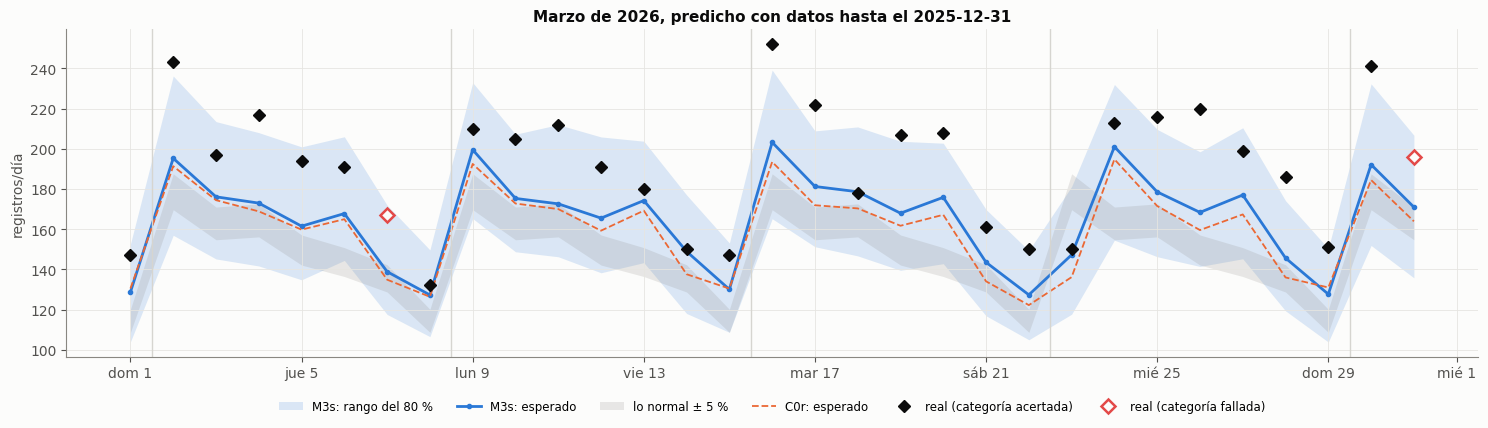

,esperado,rango 80 %,lo normal,sube si más de,baja si menos de,P(baja),P(normal),P(sube),dice,real,pasó,¿en rango?,error %,¿acertó?
día,,,,,,,,,,,,,,
domingo 1,129,104-153,114,120,109,17 %,18 %,65 %,sube,147,sube,sí,-12.4,✔
lunes 2,195,157-236,179,188,170,21 %,20 %,60 %,sube,243,sube,no,-19.6,✔
martes 3,176,145-214,163,171,155,20 %,22 %,58 %,sube,197,sube,sí,-10.6,✔
miércoles 4,173,142-208,164,173,156,24 %,25 %,51 %,sube,217,sube,no,-20.3,✔
jueves 5,161,135-201,150,157,142,17 %,23 %,59 %,sube,194,sube,sí,-16.8,✔
viernes 6,168,144-206,144,151,136,7 %,13 %,80 %,sube,191,sube,sí,-12.2,✔
sábado 7,139,118-172,136,142,129,30 %,24 %,46 %,normal,167,sube,sí,-16.9,✘
domingo 8,127,107-150,114,120,109,14 %,22 %,63 %,sube,132,sube,sí,-3.6,✔
lunes 9,200,165-233,179,188,170,14 %,19 %,66 %,sube,210,sube,sí,-5.0,✔


,días,media esperada,rango 80 %,lo normal,media real,¿en rango?,error %,dice,pasó,¿acertó?
semana,,,,,,,,,,
dom 1 a dom 1,1,128.0,104-153,114.4,147.0,sí,-13.0,sube,sube,✔
lun 2 a dom 8,7,165.5,152-179,149.9,191.6,no,-13.6,sube,sube,✔
lun 9 a dom 15,7,168.4,155-181,149.9,185.0,no,-9.0,sube,sube,✔
lun 16 a dom 22,7,168.8,156-182,149.9,196.9,no,-14.3,sube,sube,✔
lun 23 a dom 29,7,163.9,151-177,149.9,190.7,no,-14.1,sube,sube,✔
lun 30 a mar 31,2,182.5,154-212,170.8,218.5,no,-16.5,sube,sube,✔


,marzo de 2026
días con dato,31
error del día M3s %,13.1
error C0r %,16.0
error calendario %,22.1
error año pasado %,24.2
días en el rango 80 %,61.3
acierto sube/normal/baja %,93.5
tasa base %,96.8
categoría más frecuente,sube
sube: pasó / anticipó,30 / 28


In [5]:
T = mostrar("2026-03")

En la figura, los rombos negros son días en que la categoría se acertó y los rombos rojos huecos, días en que se falló; la franja gris es lo normal con su banda del 5 %. Marzo pone a prueba si el modelo puede anunciar desde diciembre un salto de nivel que dependió de una decisión administrativa (el regreso de los afiliados de Nueva EPS). Lo que el modelo sabe en diciembre es la estación: que marzo suele estar por encima de enero y febrero.

---
# 4. Julio de 2026

Predicción hecha con datos hasta el 31 de diciembre de 2025. La primera tabla es día a día; la segunda, por semana de
lunes a domingo; la tercera resume el mes.

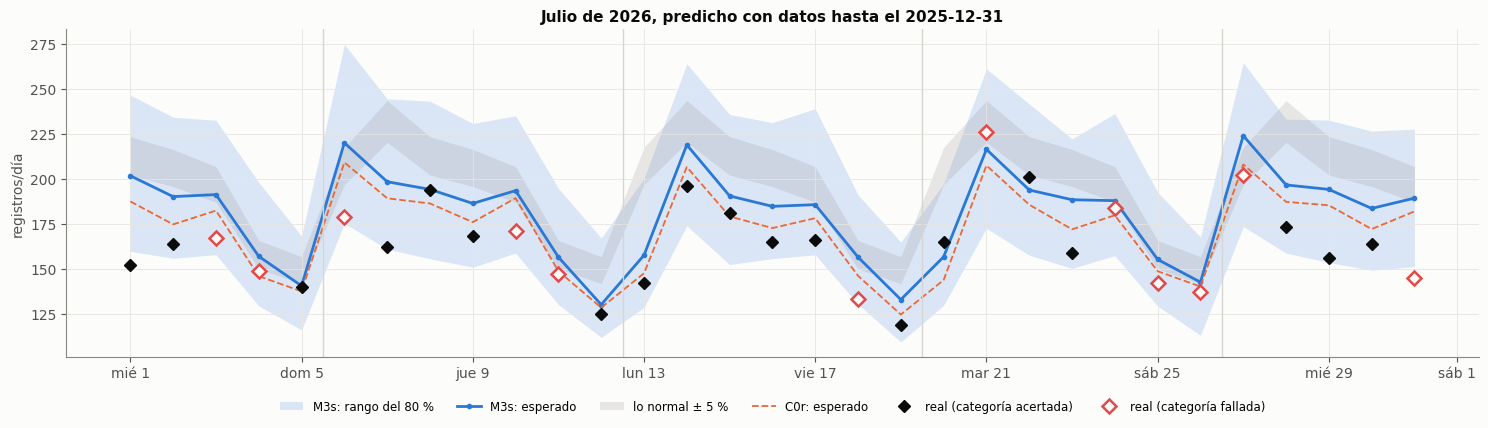

,esperado,rango 80 %,lo normal,sube si más de,baja si menos de,P(baja),P(normal),P(sube),dice,real,pasó,¿en rango?,error %,¿acertó?
día,,,,,,,,,,,,,,
miércoles 1,202,160-247,213,223,202,50 %,24 %,25 %,baja,152,baja,no,+32.7,✔
jueves 2,190,156-234,206,216,196,57 %,22 %,21 %,baja,164,baja,sí,+15.9,✔
viernes 3,191,158-233,197,207,187,44 %,29 %,27 %,normal,167,baja,sí,+14.5,✘
sábado 4,157,129-198,158,166,150,40 %,22 %,38 %,normal,149,baja,sí,+5.3,✘
domingo 5,141,116-168,149,157,142,52 %,25 %,23 %,baja,140,baja,sí,+0.4,✔
lunes 6,220,175-275,207,217,197,26 %,21 %,53 %,sube,179,baja,sí,+22.9,✘
martes 7,198,161-244,232,243,220,74 %,15 %,11 %,baja,162,baja,sí,+22.5,✔
miércoles 8,194,156-243,213,223,202,58 %,20 %,23 %,baja,194,baja,sí,+0.1,✔
jueves 9,186,151-231,206,216,196,63 %,19 %,18 %,baja,168,baja,sí,+10.9,✔


,días,media esperada,rango 80 %,lo normal,media real,¿en rango?,error %,dice,pasó,¿acertó?
semana,,,,,,,,,,
mié 1 a dom 5,5,177.8,160-196,184.6,154.4,no,+15.1,normal,baja,✘
lun 6 a dom 12,7,185.3,169-202,194.5,163.7,no,+13.2,normal,baja,✘
lun 13 a dom 19,7,178.1,163-194,194.5,157.4,no,+13.1,baja,baja,✔
lun 20 a dom 26,7,179.4,164-195,194.5,173.4,sí,+3.5,baja,baja,✔
lun 27 a vie 31,5,196.8,177-217,210.9,168.0,no,+17.1,baja,baja,✔


,julio de 2026
días con dato,31
error del día M3s %,11.9
error C0r %,7.8
error calendario %,7.2
error año pasado %,44.8
días en el rango 80 %,93.5
acierto sube/normal/baja %,61.3
tasa base %,93.5
categoría más frecuente,baja
sube: pasó / anticipó,0 / 0


In [6]:
T = mostrar("2026-07")

Julio pone a prueba lo contrario: un desplome que el modelo no puede conocer desde diciembre. La lectura útil es si el rango del 80 % alcanza a cubrir la caída o si el modelo promete una seguridad que no tiene.

---
# 5. Agosto de 2026

Predicción hecha con datos hasta el 31 de diciembre de 2025. La primera tabla es día a día; la segunda, por semana de
lunes a domingo; la tercera resume el mes.

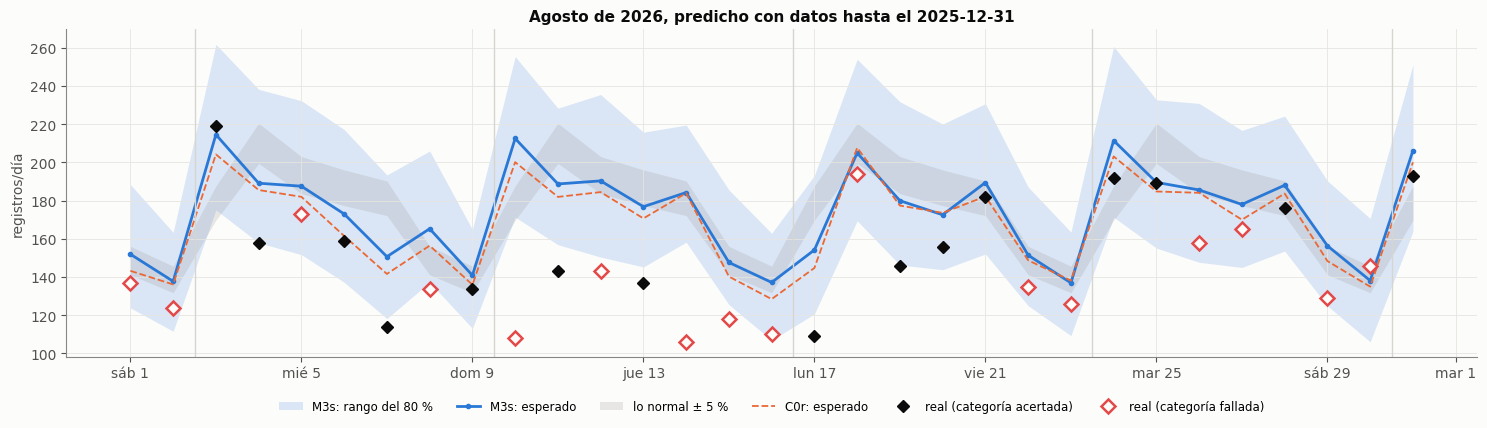

,esperado,rango 80 %,lo normal,sube si más de,baja si menos de,P(baja),P(normal),P(sube),dice,real,pasó,¿en rango?,error %,¿acertó?
día,,,,,,,,,,,,,,
sábado 1,152,124-188,149,156,141,30 %,29 %,41 %,normal,137,baja,sí,+10.9,✘
domingo 2,138,112-163,139,146,132,40 %,25 %,35 %,normal,124,baja,sí,+11.1,✘
lunes 3,215,175-262,179,188,170,8 %,12 %,80 %,sube,219,sube,sí,-2.0,✔
martes 4,189,158-238,210,220,200,60 %,19 %,21 %,baja,158,baja,sí,+19.7,✔
miércoles 5,188,152-232,193,203,184,45 %,25 %,30 %,normal,173,baja,sí,+8.4,✘
jueves 6,173,137-217,187,196,177,56 %,22 %,23 %,baja,159,baja,sí,+8.8,✔
viernes 7,151,118-193,181,190,172,78 %,10 %,12 %,baja,114,baja,no,+32.2,✔
sábado 8,165,137-206,149,156,141,15 %,20 %,65 %,sube,134,baja,no,+23.4,✘
domingo 9,141,113-165,139,146,132,36 %,25 %,38 %,normal,134,normal,sí,+5.1,✔


,días,media esperada,rango 80 %,lo normal,media real,¿en rango?,error %,dice,pasó,¿acertó?
semana,,,,,,,,,,
sáb 1 a dom 2,2,145.1,125-171,143.7,130.5,sí,+11.2,normal,baja,✘
lun 3 a dom 9,7,176.9,161-193,176.8,155.9,no,+13.5,normal,baja,✘
lun 10 a dom 16,7,178.7,163-194,176.8,123.6,no,+44.6,normal,baja,✘
lun 17 a dom 23,7,172.7,157-188,176.8,149.7,no,+15.4,normal,baja,✘
lun 24 a dom 30,7,179.5,164-195,176.8,165.0,sí,+8.8,normal,baja,✘
lun 31 a lun 31,1,205.3,164-252,178.8,193.0,sí,+6.4,sube,sube,✔


,agosto de 2026
días con dato,31
error del día M3s %,20.0
error C0r %,16.6
error calendario %,12.5
error año pasado %,56.1
días en el rango 80 %,67.7
acierto sube/normal/baja %,48.4
tasa base %,77.4
categoría más frecuente,baja
sube: pasó / anticipó,4 / 3


In [7]:
T = mostrar("2026-08")

Agosto reúne el terremoto del lunes 10, dos festivos y el nivel más bajo de Nueva EPS. Ninguno de esos hechos está en el modelo: el terremoto quedó fuera por decisión y ocurrió después del origen. Es el caso en que se espera el mayor error, y el que mejor muestra el límite de predecir con ocho meses de adelanto.

---
# 6. Los meses juntos, con septiembre

La tabla reúne los cuatro meses verificables. Septiembre viene del cuaderno 24 (el mismo modelo, también desde el 31
de diciembre de 2025), con la semana del 21 al 27 tomada de los conteos reportados.

In [8]:
P9 = pd.read_parquet(mac.CARPETA / "2026.parquet")
D9 = {k: g.set_index("fecha") for k, g in P9.groupby("modelo")}; M9 = D9["M3s"]; f9 = M9.index
ref9 = mac.vara("2026-09", "2025-12-31").reindex(f9.dayofweek).values; real9 = REAL.reindex(f9).values; hay9 = ~np.isnan(real9)
T9 = pd.DataFrame({"fecha": f9, "esperado": M9.q50.values, "q10": M9.q10.values, "q90": M9.q90.values, "normal": ref9,
                   "dice": cat(M9.q50.values, ref9), "real": real9, "pasó": np.where(hay9, cat(np.nan_to_num(real9), ref9), "—"),
                   "C0r": D9["C0r"].q50.values, "calendario": D9["normal"].q50.values, "año pasado": D9["anio_pasado"].q50.values})
T9["en rango"] = np.where(hay9, np.where((real9 >= T9.q10) & (real9 <= T9.q90), "sí", "no"), "—")
R["2026-09"] = T9
RES = pd.DataFrame({f"{MESES[pd.Timestamp(m + '-01').month]}": resumen(T) for m, T in sorted(R.items()) if resumen(T)}).T
display(RES.style.format(precision=1))

,días con dato,error del día M3s %,error C0r %,error calendario %,error año pasado %,días en el rango 80 %,acierto sube/normal/baja %,tasa base %,categoría más frecuente,sube: pasó / anticipó,normal: pasó / anticipó,baja: pasó / anticipó
marzo,31,13.1,16.0,22.1,24.2,61.3,93.5,96.8,sube,30 / 28,0 / 0,1 / 1
julio,31,11.9,7.8,7.2,44.8,93.5,61.3,93.5,baja,0 / 0,2 / 0,29 / 19
agosto,31,20.0,16.6,12.5,56.1,67.7,48.4,77.4,baja,4 / 3,3 / 3,24 / 9
septiembre,27,5.6,5.8,12.1,34.0,100.0,88.9,88.9,sube,24 / 24,3 / 0,0 / 0


De la tabla anterior se puede interpretar el desempeño real del modelo en 2026 con meses de adelanto. El error del día
es la medida principal; el acierto en sube, normal o baja solo informa cuando supera la tasa base, porque en un mes
en que casi todos los días suben, decir siempre «sube» acierta sin saber nada. Las dos últimas columnas muestran, para
cada categoría, cuántos días la vivieron y en cuántos el modelo la anticipó.

---
# 7. Octubre de 2026: la predicción guardada

Esta predicción se hizo con los datos hasta el 20 de septiembre de 2026 y se guardó antes de que existiera el dato de
octubre; no se rehace. La columna **real** se llena con los conteos que se van registrando en
`datos/triage_reportado.csv` (fuente externa) o, cuando la base se actualice, con `salidas/triage_diario.parquet`.
Para juzgar un día basta con comparar el registro real con las columnas «sube si más de» y «baja si menos de».

Predicción guardada el 2026-10-07 a las 15:13:21 (versión del código 63059ef), con datos hasta el 2026-09-20.


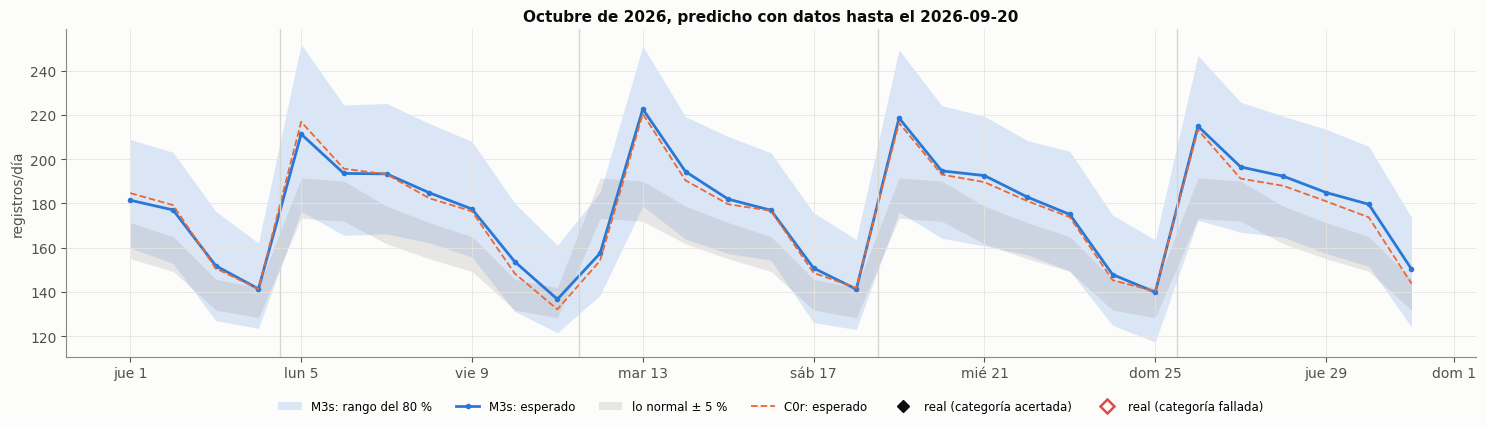

,esperado,rango 80 %,lo normal,sube si más de,baja si menos de,P(baja),P(normal),P(sube),dice,real,pasó,¿en rango?,error %,¿acertó?
día,,,,,,,,,,,,,,
jueves 1,181,160-209,163,171,155,7 %,20 %,72 %,sube,sin dato,—,—,—,—
viernes 2,177,153-203,157,165,149,8 %,21 %,71 %,sube,sin dato,—,—,—,—
sábado 3,152,127-176,139,146,132,17 %,22 %,61 %,sube,sin dato,—,—,—,—
domingo 4,141,124-162,135,142,128,19 %,32 %,49 %,normal,sin dato,—,—,—,—
lunes 5,211,176-252,182,191,173,8 %,18 %,74 %,sube,sin dato,—,—,—,—
martes 6,194,166-224,181,190,172,19 %,26 %,55 %,sube,sin dato,—,—,—,—
miércoles 7,193,166-225,170,179,162,7 %,23 %,71 %,sube,sin dato,—,—,—,—
jueves 8,185,162-216,163,171,155,6 %,22 %,72 %,sube,sin dato,—,—,—,—
viernes 9,177,156-208,157,165,149,7 %,20 %,73 %,sube,sin dato,—,—,—,—


,días,media esperada,rango 80 %,lo normal,media real,¿en rango?,error %,dice,pasó,¿acertó?
semana,,,,,,,,,,
jue 1 a dom 4,4,162.8,147-180,148.5,sin dato,—,—,sube,—,—
lun 5 a dom 11,7,180.0,164-196,161.1,sin dato,—,—,sube,—,—
lun 12 a dom 18,7,175.7,160-191,161.1,sin dato,—,—,sube,—,—
lun 19 a dom 25,7,178.4,162-195,161.1,sin dato,—,—,sube,—,—
lun 26 a sáb 31,6,185.4,167-204,165.4,sin dato,—,—,sube,—,—


Todavía no hay registros reales de octubre en la fuente ni en los conteos reportados.

In [9]:
T10, meta10, rho10 = mes("2026-10"); R["2026-10"] = T10
print(f"Predicción guardada el {meta10['creado'].replace('T', ' a las ')} (versión del código {meta10['commit']}), "
      f"con datos hasta el {meta10['origen']}.")
legible = mac.archivo("2026-10", meta10["origen"]).with_name(mac.archivo("2026-10", meta10["origen"]).name + "_tabla.csv")
if not legible.exists():                                   # la tabla tal como se publicó, una sola vez
    tabla_dia(T10).drop(columns=["real", "pasó", "¿en rango?", "error %", "¿acertó?"]).to_csv(legible, encoding="utf-8-sig")
figura(T10, f"Octubre de 2026, predicho con datos hasta el {meta10['origen']}")
display(tabla_dia(T10))
display(tabla_semana(T10, rho10).style.format(precision=1))
r = resumen(T10)
display(pd.Series(r, name="octubre de 2026").to_frame().style.format(precision=1) if r else
        Markdown("Todavía no hay registros reales de octubre en la fuente ni en los conteos reportados."))

La predicción de octubre anuncia el nivel desde el que parte el mes. Si la recuperación de septiembre continúa, los
días tenderán a quedar por encima de lo normal, que se calculó con las ocho semanas que incluyen el bache de agosto;
si el volumen vuelve a caer, se verá primero en la columna «pasó».

---
# 8. Límites del análisis

- **Cuatro meses no son una validación.** Muestran cómo falla el modelo en situaciones distintas; la cifra de
  referencia para la expectativa sigue siendo la validación de los septiembres de 2023 a 2025 del cuaderno 24.
- **Lo que se decide fuera del hospital no se puede predecir desde diciembre.** La entrada y salida de afiliados de
  Nueva EPS y el terremoto mueven el nivel más que cualquier variable del modelo.
- **Lo normal de octubre termina el 20 de septiembre** e incluye el bache de agosto, porque es lo último conocido al
  hacer la predicción. Eso hace más probable que los días de octubre se clasifiquen como «sube».
- **El rango de la semana es estrecho con adelantos largos** (cubrió el 56 % de las semanas en la validación), de modo
  que una semana fuera de rango no es por sí sola una sorpresa.
- **Los conteos reportados a mano** vienen de una fuente externa a la base y solo se usan para comparar; ninguno entra
  al entrenamiento.